In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import pandas as pd
from src.data.data import build_auctions
from src.features.build_features import build_features
from src.models.ridge import walk_forward_ridge

import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# team auction table (src/data/data.py), weekly only, KORR dropped as in the EDA
auctions = build_auctions(product="mFRR")
auctions = auctions[auctions["freq"] == "weekly"]
auctions = auctions[~auctions["auction_id"].str.contains("KORR")].reset_index(drop=True)
# build_features and ridge.py still use the old column names
auctions = auctions.rename(columns={
    "marginal": "marginal_price", "y": "log10_price",
    "gc": "gate_closure_time_utc", "avail": "available_time_utc",
})
features = build_features(auctions)

In [2]:
preds = walk_forward_ridge(features, start_test="2024-01-01", end_test="2024-12-31")
print(len(preds), "auctions predicted")
preds.head()

106 auctions predicted


,auction_id,direction,gate_closure_time_utc,log10_price,pred_ridge,pred_baseline
0,TRL_24_KW02_up,upwards,2024-01-02 12:00:00+00:00,2.608526,2.612493,2.608526
1,TRL_24_KW03_up,upwards,2024-01-09 12:00:00+00:00,2.773055,2.610017,2.608526
2,TRL_24_KW04_up,upwards,2024-01-16 12:00:00+00:00,2.767156,2.741489,2.773055
3,TRL_24_KW05_up,upwards,2024-01-23 12:00:00+00:00,2.740363,2.751800,2.767156
4,TRL_24_KW06_up,upwards,2024-01-30 12:00:00+00:00,2.774517,2.742515,2.740363


In [3]:
mae = pd.DataFrame({
    model: (preds[f"pred_{model}"] - preds["log10_price"]).abs().groupby(preds["direction"]).mean()
    for model in ["baseline", "ridge"]
}).round(3)
mae

,baseline,ridge
direction,,
downwards,0.126,0.128
upwards,0.046,0.053


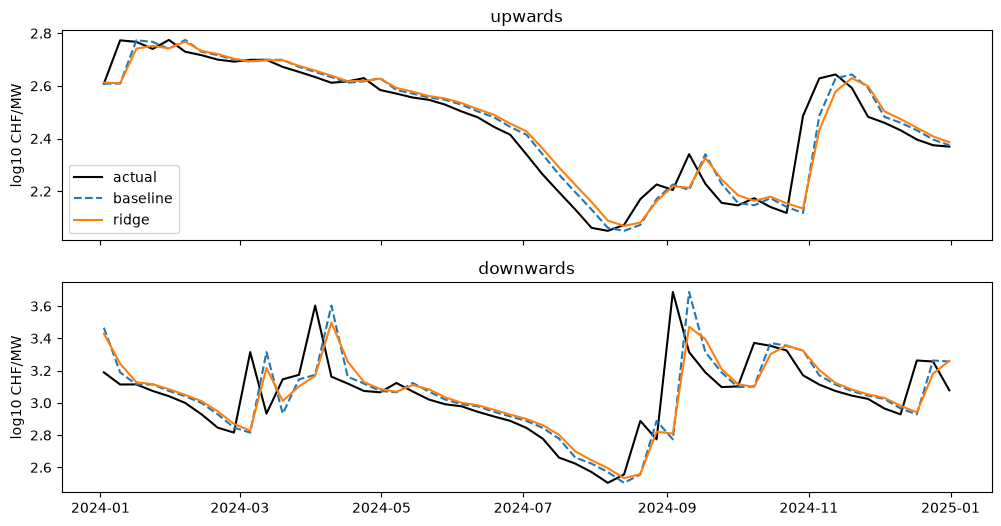

In [4]:

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, direction in zip(axes, ["upwards", "downwards"]):
    d = preds[preds["direction"] == direction]
    ax.plot(d["gate_closure_time_utc"], d["log10_price"], "k-", label="actual")
    ax.plot(d["gate_closure_time_utc"], d["pred_baseline"], "--", label="baseline")
    ax.plot(d["gate_closure_time_utc"], d["pred_ridge"], "-", label="ridge")
    ax.set_title(direction)
    ax.set_ylabel("log10 CHF/MW")
axes[0].legend()
plt.show()

In [5]:
tr = features[features["available_time_utc"] < "2024-01-01"].dropna(subset=["lag1", "lag2", "lag3"])
for direction in ["upwards", "downwards"]:
    d = tr[tr["direction"] == direction]
    m = Ridge(alpha=1.0).fit(d[["lag1", "lag2", "lag3"]], d["log10_price"])
    print(direction, "coef:", m.coef_.round(3), "intercept:", round(m.intercept_, 3))

upwards coef: [0.804 0.092 0.078] intercept: 0.07
downwards coef: [ 0.786  0.197 -0.008] intercept: 0.082
